<a href="https://colab.research.google.com/github/shiv6292/ANN-Loan-Approval-Model/blob/main/Loan_Approval_ANN_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
OUT_DIR = "loan_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
def generate_data(n=5000):
    age = np.random.randint(21, 66, n)
    income = np.random.normal(60000, 25000, n).clip(15000, 250000)
    credit_score = np.random.normal(680, 70, n).clip(300, 850)
    loan_amount = np.random.normal(150000, 90000, n).clip(10000, 600000)
    loan_term = np.random.choice([12, 24, 36, 48, 60, 84, 120], n)
    employment_years = np.clip(age - 21 - np.random.randint(0, 8, n), 0, 40)
    existing_debt = np.random.normal(20000, 15000, n).clip(0, 150000)
    owns_property = np.random.binomial(1, 0.45, n)

    dti = (existing_debt + loan_amount) / income
    score = (0.015 * (credit_score - 650)
             + 0.00001 * (income - 50000)
             - 0.9 * dti
             + 0.05 * employment_years
             + 0.6 * owns_property
             + 0.4)
    score += np.random.normal(0, 0.4, n)          # noise
    prob = 1 / (1 + np.exp(-score))
    approved = (np.random.rand(n) < prob).astype(int)

    return pd.DataFrame({
        "age": age,
        "income": income.round(0),
        "credit_score": credit_score.round(0),
        "loan_amount": loan_amount.round(0),
        "loan_term_months": loan_term,
        "employment_years": employment_years,
        "existing_debt": existing_debt.round(0),
        "owns_property": owns_property,
        "approved": approved,
    })

df = generate_data(5000)
df.to_csv(f"{OUT_DIR}/synthetic_loan_data.csv", index=False)

print("Shape:", df.shape)
print("Approval rate: {:.1f}%".format(df["approved"].mean() * 100))
df.head(10)

Shape: (5000, 9)
Approval rate: 40.4%


,age,income,credit_score,loan_amount,loan_term_months,employment_years,existing_debt,owns_property,approved
0,59,107603.0,729.0,58658.0,60,36,0.0,1,1
1,49,100649.0,675.0,96063.0,84,22,23787.0,0,1
2,35,115470.0,661.0,185518.0,120,9,20732.0,1,0
3,63,56024.0,655.0,182247.0,24,40,5999.0,1,0
4,28,67391.0,676.0,74121.0,36,2,43530.0,0,1
5,41,22084.0,649.0,44951.0,120,14,29104.0,0,0
6,59,96923.0,726.0,175343.0,120,32,30378.0,1,1
7,39,30806.0,652.0,133633.0,12,13,12690.0,1,0
8,43,65419.0,792.0,344149.0,84,22,19980.0,1,0
9,31,32567.0,783.0,153294.0,12,7,29411.0,0,0


,age,income,credit_score,loan_amount,loan_term_months,employment_years,existing_debt,owns_property,approved
count,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0
mean,43.1,59702.8,679.8,154884.4,55.0,18.8,20434.6,0.4,0.4
std,12.9,24543.9,68.7,86285.2,34.3,12.6,13684.9,0.5,0.5
min,21.0,15000.0,405.0,10000.0,12.0,0.0,0.0,0.0,0.0
25%,32.0,41990.2,634.0,90461.5,24.0,7.0,9634.0,0.0,0.0
50%,43.0,59236.5,680.0,153034.5,48.0,19.0,20004.0,0.0,0.0
75%,54.0,76695.8,726.0,214440.8,84.0,30.0,29756.5,1.0,1.0
max,65.0,158156.0,850.0,553118.0,120.0,40.0,68231.0,1.0,1.0


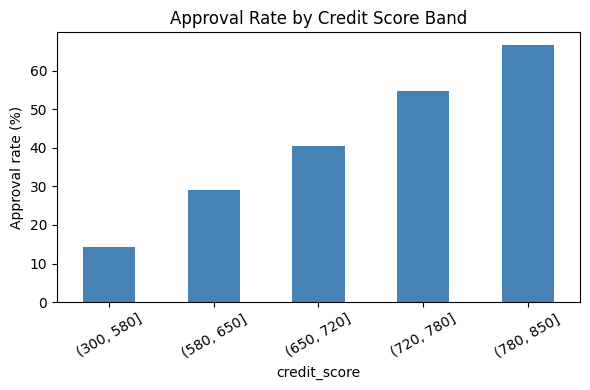

In [3]:
display(df.describe().round(1))

bands = pd.cut(df["credit_score"], bins=[300, 580, 650, 720, 780, 850])
rate = df.groupby(bands, observed=True)["approved"].mean() * 100
plt.figure(figsize=(6, 4))
rate.plot(kind="bar", color="steelblue")
plt.title("Approval Rate by Credit Score Band")
plt.ylabel("Approval rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/approval_by_credit_score.png", dpi=150)
plt.show()

In [4]:
X = df.drop(columns="approved")
y = df["approved"]
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training samples:", X_train_s.shape[0])
print("Testing samples :", X_test_s.shape[0])

Training samples: 4000
Testing samples : 1000


In [5]:
model = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(16, activation="relu", name="hidden_1"),
    layers.Dropout(0.2),
    layers.Dense(8, activation="relu", name="hidden_2"),
    layers.Dense(1, activation="sigmoid", name="output"),
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train_s, y_train.values,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6297 - loss: 0.6417 - val_accuracy: 0.7425 - val_loss: 0.5754
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7603 - loss: 0.5375 - val_accuracy: 0.7675 - val_loss: 0.4991
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7750 - loss: 0.4846 - val_accuracy: 0.7700 - val_loss: 0.4706
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7841 - loss: 0.4580 - val_accuracy: 0.7775 - val_loss: 0.4635
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7875 - loss: 0.4523 - val_accuracy: 0.7837 - val_loss: 0.4609
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7887 - loss: 0.4434 - val_accuracy: 0.7812 - val_loss: 0.4601
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7909 - loss: 0.4461 - val_accuracy: 0.7825 - val_loss: 0.4586
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7903 - loss: 0.4406 - val_acc

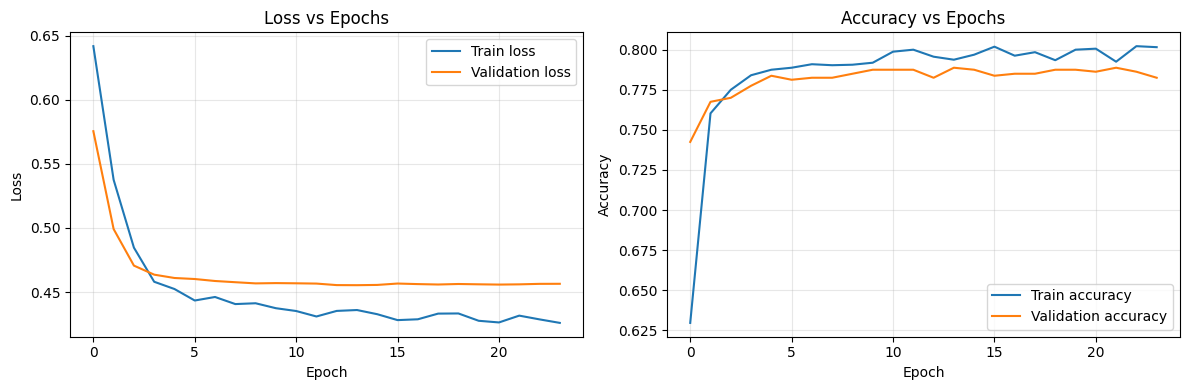

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="Train loss")
ax[0].plot(history.history["val_loss"], label="Validation loss")
ax[0].set_title("Loss vs Epochs"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(history.history["accuracy"], label="Train accuracy")
ax[1].plot(history.history["val_accuracy"], label="Validation accuracy")
ax[1].set_title("Accuracy vs Epochs"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150)
plt.show()

In [8]:
y_prob = model.predict(X_test_s, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {auc:.4f}")
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=["Rejected", "Approved"]))

Accuracy : 0.8150
Precision: 0.7772
Recall   : 0.7599
F1-score : 0.7685
ROC-AUC  : 0.8840

Classification Report:
               precision    recall  f1-score   support

    Rejected       0.84      0.85      0.85       596
    Approved       0.78      0.76      0.77       404

    accuracy                           0.81      1000
   macro avg       0.81      0.81      0.81      1000
weighted avg       0.81      0.81      0.81      1000



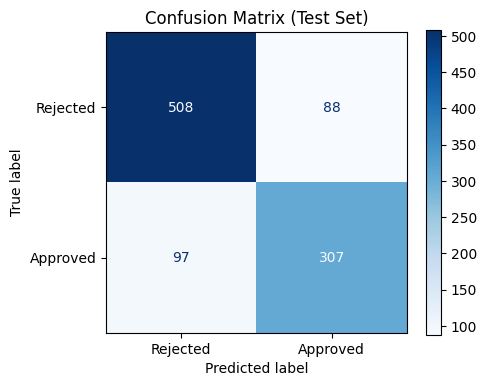

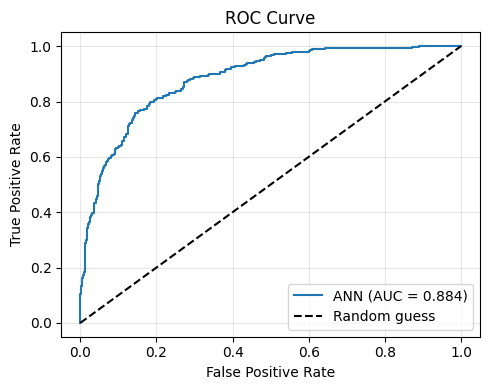

In [9]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Rejected", "Approved"]).plot(ax=ax, cmap="Blues")
ax.set_title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150)
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"ANN (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/roc_curve.png", dpi=150)
plt.show()

In [10]:
samples = pd.DataFrame([
    # age, income, credit, loan_amt, term, emp_yrs, debt, property
    [35, 90000, 780, 120000, 60, 10, 10000, 1],   # strong applicant
    [24, 30000, 560, 250000, 84, 1, 40000, 0],    # weak applicant
    [45, 60000, 690, 150000, 48, 15, 20000, 1],   # average applicant
    [29, 45000, 620, 200000, 60, 4, 30000, 0],    # risky applicant
], columns=feature_names)

sample_prob = model.predict(scaler.transform(samples), verbose=0).ravel()
samples["approval_probability"] = sample_prob.round(3)
samples["decision"] = np.where(sample_prob >= 0.5, "APPROVED", "REJECTED")
samples

,age,income,credit_score,loan_amount,loan_term_months,employment_years,existing_debt,owns_property,approval_probability,decision
0,35,90000,780,120000,60,10,10000,1,0.938,APPROVED
1,24,30000,560,250000,84,1,40000,0,0.001,REJECTED
2,45,60000,690,150000,48,15,20000,1,0.536,APPROVED
3,29,45000,620,200000,60,4,30000,0,0.016,REJECTED


In [11]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def predict_loan(age, income, credit_score, loan_amount, loan_term_months,
                 employment_years, existing_debt, owns_property):
    row = pd.DataFrame([[age, income, credit_score, loan_amount, loan_term_months,
                         employment_years, existing_debt, owns_property]],
                       columns=feature_names)
    return float(model.predict(scaler.transform(row), verbose=0)[0][0])

style = {"description_width": "170px"}
lay = widgets.Layout(width="360px")

w_age    = widgets.IntText(value=30, description="Age (years)", style=style, layout=lay)
w_income = widgets.FloatText(value=70000, description="Yearly income (Rs)", style=style, layout=lay)
w_credit = widgets.IntText(value=720, description="Credit score (300-850)", style=style, layout=lay)
w_loan   = widgets.FloatText(value=100000, description="Loan amount (Rs)", style=style, layout=lay)
w_term   = widgets.Dropdown(options=[12, 24, 36, 48, 60, 84, 120], value=48,
                            description="Loan term (months)", style=style, layout=lay)
w_emp    = widgets.IntText(value=6, description="Employment years", style=style, layout=lay)
w_debt   = widgets.FloatText(value=15000, description="Existing debt (Rs)", style=style, layout=lay)
w_prop   = widgets.Dropdown(options=[("Yes", 1), ("No", 0)], value=1,
                            description="Owns property?", style=style, layout=lay)

btn = widgets.Button(description="Predict", button_style="primary", icon="check")
out = widgets.Output()

def on_click(_):
    with out:
        clear_output()
        if w_income.value <= 0:
            print("Income must be greater than 0."); return
        if not (300 <= w_credit.value <= 850):
            print("Credit score must be between 300 and 850."); return
        p = predict_loan(w_age.value, w_income.value, w_credit.value, w_loan.value,
                         w_term.value, w_emp.value, w_debt.value, w_prop.value)
        approved = p >= 0.5
        color = "#1a7f37" if approved else "#c62828"
        label = "LOAN APPROVED" if approved else "LOAN REJECTED"
        dti = (w_debt.value + w_loan.value) / w_income.value
        display(widgets.HTML(
            f"<div style='padding:12px;border:2px solid {color};border-radius:8px;width:360px'>"
            f"<b style='color:{color};font-size:20px'>{label}</b><br>"
            f"Approval probability: <b>{p:.1%}</b><br>"
            f"Debt-to-income ratio: {dti:.2f}</div>"))

btn.on_click(on_click)
display(widgets.VBox([w_age, w_income, w_credit, w_loan, w_term, w_emp, w_debt, w_prop, btn, out]))

In [13]:
print("Enter applicant details:")
age   = int(input("Age: "))
inc   = float(input("Yearly income: "))
cs    = int(input("Credit score (300-850): "))
amt   = float(input("Loan amount: "))
term  = int(input("Loan term in months (12/24/36/48/60/84/120): "))
emp   = int(input("Employment years: "))
debt  = float(input("Existing debt: "))
prop  = int(input("Owns property? (1 = yes, 0 = no): "))

p = predict_loan(age, inc, cs, amt, term, emp, debt, prop)
print(f"\nApproval probability: {p:.1%}")
print("Decision:", "LOAN APPROVED" if p >= 0.5 else "LOAN REJECTED")

Enter applicant details:
Age: 30
Yearly income: 1000000
Credit score (300-850): 400
Loan amount: 10000000
Loan term in months (12/24/36/48/60/84/120): 60
Employment years: 5
Existing debt: 2500000
Owns property? (1 = yes, 0 = no): 1

Approval probability: 0.0%
Decision: LOAN REJECTED
